# **Projeto Integrador**

## **Análise do comportamento da carga do SIN durante períodos de El Niño e La Niña entre 2023 e 2025**

### **Contexto**

A carga do SIN apresenta variações ao longo do tempo decorrentes de diferentes fatores, incluindo aspectos econômicos, sazonais e meteorológicos. Entre os fenômenos climáticos de grande escala que podem contribuir para modificar as condições meteorológicas no Brasil estão o El Niño e a La Niña, fases opostas do fenômeno El Niño-Oscilação Sul (ENOS). Entre 2023 e 2025 ocorreram períodos associados a ambas as fases do fenômeno, possibilitando a comparação do comportamento da carga do SIN sob diferentes contextos climáticos. Nesse sentido, o projeto busca identificar diferenças na magnitude, sazonalidade e no perfil horário da carga entre os períodos considerados de El Niño e La Niña. A análise não pretende estabelecer uma relação causal entre ENOS e a carga, mas identificar padrões e diferenças existentes nos dados que possam contribuir para compreender o comportamento da demanda de energia em diferentes condições climáticas.

### **Pergunta analítica**
Como o comportamento da carga do SIN se diferenciou entre os períodos de El Niño e La Niña observados entre 2023 e 2025?
## **Objetivo**
Comparar o comportamento da carga do SIN nos períodos classificados como El Niño e La Niña entre 2023 e 2025, identificando diferenças na magnitude, sazonalidade, perfil horário e ocorrência de valores elevados de carga.


In [97]:
### Instalando biliotecas no colab

!pip install pandas numpy matplotlib seaborn

In [98]:
### importando bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [51]:
### upload do arquivo

from google.colab import files

uploaded = files.upload()

Saving BALANCO_ENERGIA_SUBSISTEMA_2023.csv to BALANCO_ENERGIA_SUBSISTEMA_2023 (1).csv
Saving BALANCO_ENERGIA_SUBSISTEMA_2024.csv to BALANCO_ENERGIA_SUBSISTEMA_2024 (1).csv
Saving BALANCO_ENERGIA_SUBSISTEMA_2025.csv to BALANCO_ENERGIA_SUBSISTEMA_2025 (1).csv


In [52]:
print("Arquivos carregados:")

for arquivo in uploaded.keys():
    print("-", arquivo)

Arquivos carregados:
- BALANCO_ENERGIA_SUBSISTEMA_2023 (1).csv
- BALANCO_ENERGIA_SUBSISTEMA_2024 (1).csv
- BALANCO_ENERGIA_SUBSISTEMA_2025 (1).csv


In [53]:
#definindo arquivos

arquivos = {
    2023: "BALANCO_ENERGIA_SUBSISTEMA_2023.csv",
    2024: "BALANCO_ENERGIA_SUBSISTEMA_2024.csv",
    2025: "BALANCO_ENERGIA_SUBSISTEMA_2025.csv"
}

In [54]:
#lendo arquivos

dfs = {}

for ano, arquivo in arquivos.items():

    dfs[ano] = pd.read_csv(
        arquivo,
        sep=";",
        encoding="utf-8",
        decimal=","
    )

    print(
        f"{ano}: "
        f"{dfs[ano].shape[0]:,} linhas x "
        f"{dfs[ano].shape[1]} colunas"
    )

2023: 43,800 linhas x 9 colunas
2024: 43,920 linhas x 9 colunas
2025: 43,800 linhas x 9 colunas


In [55]:
#### comparando colunas dos arquivos para depois concatenar

for ano, dados in dfs.items():

    print(f"\n{ano}:")
    print(dados.columns.tolist())

mesmas_colunas = (
  list(dfs[2023].columns) ==
  list(dfs[2024].columns) ==
  list(dfs[2025].columns)
)

print("Os três arquivos possuem as mesmas colunas?", mesmas_colunas)


2023:
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar', 'val_carga', 'val_intercambio']

2024:
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar', 'val_carga', 'val_intercambio']

2025:
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar', 'val_carga', 'val_intercambio']
Os três arquivos possuem as mesmas colunas? True


In [56]:
### identificando o arquivo de origem

for ano, dados in dfs.items():
    dados["ano_arquivo"] = ano

In [57]:
### concatenando arquivos

df = pd.concat(
    [dfs[2023], dfs[2024], dfs[2025]],
    ignore_index=True
)
print(
    f"Base consolidada: "
    f"{df.shape[0]:,} linhas x "
    f"{df.shape[1]} colunas"
)
df.head()
df["ano_arquivo"].value_counts().sort_index()

Base consolidada: 131,520 linhas x 10 colunas


,count
ano_arquivo,
2023,43800
2024,43920
2025,43800


In [58]:
### diagnóstico dos 3 arquivos
diagnostico_arquivos = []

for ano, dados in dfs.items():

    diagnostico_arquivos.append({
        "Ano": ano,
        "Linhas": dados.shape[0],
        "Colunas": dados.shape[1],
        "Duplicados": dados.duplicated().sum(),
        "Valores ausentes": dados.isna().sum().sum()
    })

diagnostico_arquivos = pd.DataFrame(
    diagnostico_arquivos
)

diagnostico_arquivos

,Ano,Linhas,Colunas,Duplicados,Valores ausentes
0,2023,43800,10,0,0
1,2024,43920,10,0,0
2,2025,43800,10,0,0


In [62]:
## validando ano do arquivo e ano da data

df["din_instante"] = pd.to_datetime(
    df["din_instante"],
    errors="coerce"
)

print("Período da base:")
print("Início:", df["din_instante"].min())
print("Fim:", df["din_instante"].max())

print(
    "\nDatas que não puderam ser convertidas:",
    df["din_instante"].isna().sum()
)

df["ano_data"] = df["din_instante"].dt.year

divergencias_ano = (
    df["ano_arquivo"] != df["ano_data"]
).sum()

print(
    "Registros em que o ano do arquivo "
    "não coincide com a data:",
    divergencias_ano
)

Período da base:
Início: 2023-01-01 00:00:00
Fim: 2025-12-31 23:00:00

Datas que não puderam ser convertidas: 0
Registros em que o ano do arquivo não coincide com a data: 0


In [63]:
### quantidade de registros por ano e por subsistema
registros_ano = (
    df.groupby("ano_data")
    .size()
    .reset_index(name="quantidade")
)

registros_ano
pd.crosstab(
    df["ano_data"],
    df["nom_subsistema"]
)

nom_subsistema,NORDESTE,NORTE,SISTEMA INTERLIGADO NACIONAL,SUDESTE/CENTRO-OESTE,SUL
ano_data,,,,,
2023,8760,8760,8760,8760,8760
2024,8784,8784,8784,8784,8784
2025,8760,8760,8760,8760,8760


# **Diagnostico da base concatenada**
Após a consolidação dos arquivos de 2023, 2024 e 2025, foram realizadas verificações de qualidade dos dados, considerando valores ausentes, registros duplicados, consistência temporal e distribuição das observações entre os subsistemas.

Essas verificações foram realizadas antes da construção da base analítica, evitando a realização de tratamentos sem uma avaliação prévia de sua necessidade.


In [64]:
#verifica dimensões dos dados
print("Dimensão da base consolidada:")
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")

diagnostico = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "percentual_ausentes": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique()
})

display(diagnostico)

Dimensão da base consolidada:
131,520 linhas x 11 colunas


,tipo,ausentes,percentual_ausentes,valores_unicos
id_subsistema,object,0,0.00,5
nom_subsistema,object,0,0.00,5
din_instante,datetime64[ns],0,0.00,26304
val_gerhidraulica,object,0,0.00,131300
val_gertermica,object,0,0.00,130393
val_gereolica,object,0,0.00,107587
val_gersolar,object,0,0.00,84283
val_carga,object,0,0.00,131228
val_intercambio,object,0,0.00,115390
ano_arquivo,int64,0,0.00,3


In [65]:
#verificar duplicatas
duplicados_completos = df.duplicated().sum()

duplicados_chave = df.duplicated(
    subset=["din_instante", "id_subsistema"]
).sum()

print(f"Registros completamente duplicados: {duplicados_completos:,}")
print(
    "Duplicidades na combinação "
    f"din_instante + id_subsistema: {duplicados_chave:,}"
)

Registros completamente duplicados: 0
Duplicidades na combinação din_instante + id_subsistema: 0


In [66]:
#verificar período temporal

df["din_instante"] = pd.to_datetime(
    df["din_instante"],
    errors="coerce"
)
print("Início da série:", df["din_instante"].min())
print("Fim da série:", df["din_instante"].max())
print(
    "Datas não convertidas:",
    df["din_instante"].isna().sum()
)

Início da série: 2023-01-01 00:00:00
Fim da série: 2025-12-31 23:00:00
Datas não convertidas: 0


In [67]:
#validar o ano

df["ano_data"] = df["din_instante"].dt.year

divergencias = (
    df["ano_arquivo"] != df["ano_data"]
).sum()

print(
    "Registros com divergência entre "
    f"ano do arquivo e ano da data: {divergencias:,}"
)
pd.crosstab(
    df["ano_arquivo"],
    df["ano_data"],
    margins=True
)

Registros com divergência entre ano do arquivo e ano da data: 0


ano_data,2023,2024,2025,All
ano_arquivo,,,,
2023,43800,0,0,43800
2024,0,43920,0,43920
2025,0,0,43800,43800
All,43800,43920,43800,131520


In [68]:
#verificar os subsistemas
subsistemas = (
    df[
        ["id_subsistema", "nom_subsistema"]
    ]
    .drop_duplicates()
    .sort_values("id_subsistema")
)

display(subsistemas)

,id_subsistema,nom_subsistema
1,N,NORTE
0,NE,NORDESTE
4,S,SUL
3,SE,SUDESTE/CENTRO-OESTE
2,SIN,SISTEMA INTERLIGADO NACIONAL


In [69]:
###filtrando o SIN
df_sin = df[
    df["id_subsistema"] == "SIN"
].copy()

print(f"Quantidade de registros do SIN: {len(df_sin):,}")

df_sin.head()

df_sin[
    ["id_subsistema", "nom_subsistema"]
].drop_duplicates()

df_sin.groupby("ano_data").size()

Quantidade de registros do SIN: 26,304


,0
ano_data,
2023,8760
2024,8784
2025,8760


In [70]:
#### avaliando a variável da carga

df_sin["val_carga"].describe()

,val_carga
count,26304
unique,26216
top,83659.69
freq,2


In [71]:
df_sin["val_carga"] = pd.to_numeric(
    df_sin["val_carga"],
    errors="coerce"
)

In [72]:
print(
    "Valores ausentes:",
    df_sin["val_carga"].isna().sum()
)

print(
    "Valores iguais a zero:",
    (df_sin["val_carga"] == 0).sum()
)

print(
    "Valores negativos:",
    (df_sin["val_carga"] < 0).sum()
)

Valores ausentes: 0
Valores iguais a zero: 0
Valores negativos: 0


In [73]:
#criando as variaveis temporais

df_sin["ano"] = df_sin["din_instante"].dt.year
df_sin["mes"] = df_sin["din_instante"].dt.month
df_sin["hora"] = df_sin["din_instante"].dt.hour
df_sin["data"] = df_sin["din_instante"].dt.date
df_sin["dia_semana"] = df_sin["din_instante"].dt.dayofweek

df_sin["tipo_dia"] = np.where(
    df_sin["dia_semana"] >= 5,
    "Fim de semana",
    "Segunda a sexta"
)

In [74]:
df_sin[
    [
        "din_instante",
        "ano",
        "mes",
        "hora",
        "dia_semana",
        "tipo_dia"
    ]
].head()

,din_instante,ano,mes,hora,dia_semana,tipo_dia
2,2023-01-01 00:00:00,2023,1,0,6,Fim de semana
7,2023-01-01 01:00:00,2023,1,1,6,Fim de semana
12,2023-01-01 02:00:00,2023,1,2,6,Fim de semana
17,2023-01-01 03:00:00,2023,1,3,6,Fim de semana
22,2023-01-01 04:00:00,2023,1,4,6,Fim de semana


# **Classificador de períodos ENOS**

Classificação dos períodos em anos de El Niño, La Niña e Neutro/Transição. De janeiro a abril de 2023 estivemos em La Niña, após isso tivemos um período de neutralidade/transição e então a partir de junho um El Niño que durou até maio de 2024. Após isso, um breve período de neutralidade e então novamente uma La Niña iniciou no mês de setembro de 2025.

In [75]:
#classificar Enso
def classificar_enso(data):

    # La Niña - janeiro a março de 2023
    if pd.Timestamp("2023-01-01") <= data < pd.Timestamp("2023-04-01"):
        return "La Niña"

    # El Niño - junho de 2023 a abril de 2024
    elif pd.Timestamp("2023-06-01") <= data < pd.Timestamp("2024-05-01"):
        return "El Niño"

    # La Niña - setembro a dezembro de 2025
    elif pd.Timestamp("2025-09-01") <= data < pd.Timestamp("2026-01-01"):
        return "La Niña"

    else:
        return "Neutro/Transição"


df_sin["fase_enso"] = (
    df_sin["din_instante"]
    .apply(classificar_enso)
)

In [76]:
tabela_enso = pd.crosstab(
    df_sin["ano"],
    df_sin["fase_enso"],
    margins=True
)

display(tabela_enso)

fase_enso,El Niño,La Niña,Neutro/Transição,All
ano,,,,
2023,5136,2160,1464,8760
2024,2904,0,5880,8784
2025,0,2928,5832,8760
All,8040,5088,13176,26304


In [77]:
resumo_enso = (
    df_sin
    .groupby("fase_enso")["din_instante"]
    .agg(
        inicio="min",
        fim="max",
        quantidade="count"
    )
)

display(resumo_enso)

,inicio,fim,quantidade
fase_enso,,,
El Niño,2023-06-01,2024-04-30 23:00:00,8040
La Niña,2023-01-01,2025-12-31 23:00:00,5088
Neutro/Transição,2023-04-01,2025-08-31 23:00:00,13176


In [78]:
#retirar os períodos de neutralidade/transição, sem apagar esses registros de df_sin

df_enso = df_sin[
    df_sin["fase_enso"].isin(
        ["El Niño", "La Niña"]
    )
].copy()

print(
    f"Total de observações da análise: "
    f"{len(df_enso):,}"
)

display(
    df_enso["fase_enso"]
    .value_counts()
    .to_frame("observacoes")
)

Total de observações da análise: 13,128


,observacoes
fase_enso,
El Niño,8040
La Niña,5088


# **Análise exploratória**

### **Comparação geral da carga**

Inicialmente, foram calculadas estatísticas descritivas da carga para os períodos classificados como El Niño e La Niña. Foram consideradas medidas de tendência central, dispersão e extremos, permitindo uma primeira comparação da magnitude e da variabilidade da carga entre os períodos analisados.

In [79]:
resumo_carga = (
    df_enso
    .groupby("fase_enso")["val_carga"]
    .agg(
        observacoes="count",
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        desvio_padrao="std"
    )
)

resumo_carga["p95"] = (
    df_enso
    .groupby("fase_enso")["val_carga"]
    .quantile(0.95)
)

display(resumo_carga.round(2))

,observacoes,media,mediana,minimo,maximo,desvio_padrao,p95
fase_enso,,,,,,,
El Niño,8040,"77,212.95","77,300.09","51,841.39","102,086.33","10,218.87","93,344.70"
La Niña,5088,"76,889.21","76,615.92","46,389.75","97,648.66","9,227.44","91,441.06"


In [80]:
#diferença da carga média

medias = (
    df_enso
    .groupby("fase_enso")["val_carga"]
    .mean()
)

media_el_nino = medias["El Niño"]
media_la_nina = medias["La Niña"]

diferenca_absoluta = (
    media_el_nino - media_la_nina
)

diferenca_percentual = (
    diferenca_absoluta /
    media_la_nina * 100
)

print(
    f"Carga média - El Niño: "
    f"{media_el_nino:,.2f} MWmed"
)

print(
    f"Carga média - La Niña: "
    f"{media_la_nina:,.2f} MWmed"
)

print(
    f"Diferença absoluta: "
    f"{diferenca_absoluta:,.2f} MWmed"
)

print(
    f"Diferença percentual: "
    f"{diferenca_percentual:.2f}%"
)

Carga média - El Niño: 77,212.95 MWmed
Carga média - La Niña: 76,889.21 MWmed
Diferença absoluta: 323.75 MWmed
Diferença percentual: 0.42%


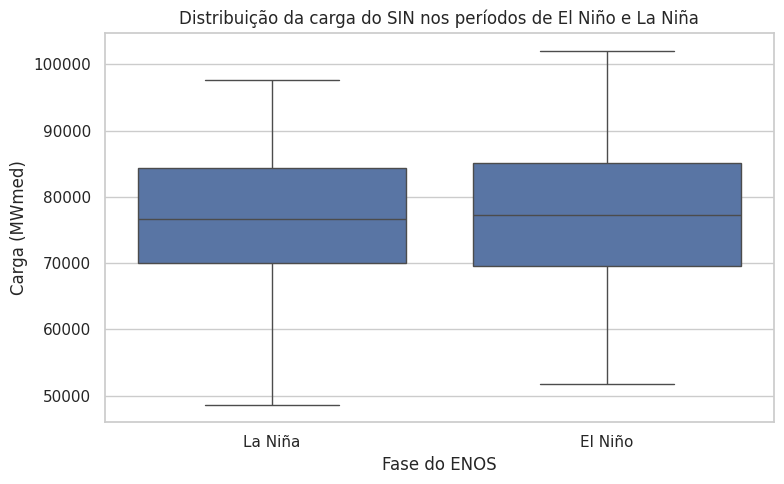

In [81]:
#boxplot de distribuição da carga nos periodos de El Nino e La Nina

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_enso,
    x="fase_enso",
    y="val_carga",
    order=["La Niña", "El Niño"],
    showfliers=False
)

plt.title(
    "Distribuição da carga do SIN nos períodos de El Niño e La Niña"
)

plt.xlabel("Fase do ENOS")
plt.ylabel("Carga (MWmed)")

plt.tight_layout()
plt.show()

### **Comportamento Mensal**

Em seguida, foi analisada a carga média mensal nos períodos selecionados. Essa etapa permite visualizar a variação da carga ao longo do tempo e verificar a importância da sazonalidade para a comparação entre El Niño e La Niña.

In [82]:
df_enso["ano_mes"] = (
    df_enso["din_instante"]
    .dt.to_period("M")
    .astype(str)
)

mensal = (
    df_enso
    .groupby(
        ["fase_enso", "ano_mes"]
    )["val_carga"]
    .mean()
    .reset_index(
        name="carga_media"
    )
)

display(mensal.round(2))

,fase_enso,ano_mes,carga_media
0,El Niño,2023-06,"69,102.13"
1,El Niño,2023-07,"68,973.00"
2,El Niño,2023-08,"72,498.71"
3,El Niño,2023-09,"75,715.27"
4,El Niño,2023-10,"77,253.26"
5,El Niño,2023-11,"80,659.13"
6,El Niño,2023-12,"80,636.47"
7,El Niño,2024-01,"79,743.46"
8,El Niño,2024-02,"82,766.54"
9,El Niño,2024-03,"82,499.62"


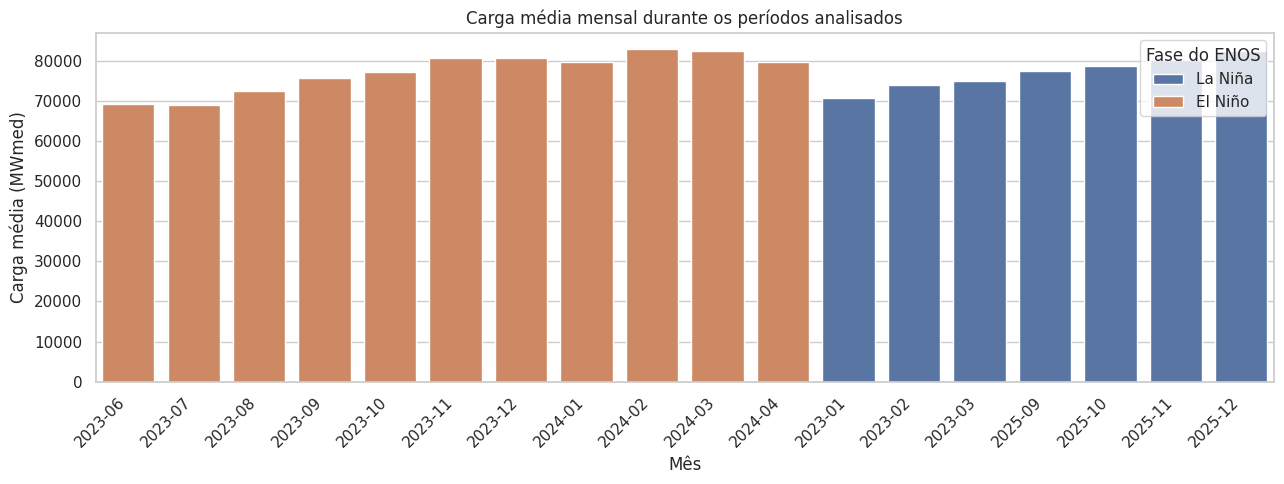

In [83]:
## grafico da carga média mensal nos periodos de enso

plt.figure(figsize=(13, 5))

sns.barplot(
    data=mensal,
    x="ano_mes",
    y="carga_media",
    hue="fase_enso",
    hue_order=["La Niña", "El Niño"]
)

plt.title(
    "Carga média mensal durante os períodos analisados"
)

plt.xlabel("Mês")
plt.ylabel("Carga média (MWmed)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Fase do ENOS"
)

plt.tight_layout()
plt.show()

In [87]:
## identificação dos meses de maior e menor carga

maior_mes = mensal.loc[
    mensal["carga_media"].idxmax()
]

menor_mes = mensal.loc[
    mensal["carga_media"].idxmin()
]

print("Maior carga média mensal:")
display(maior_mes.to_frame().T)

print("\nMenor carga média mensal:")
display(menor_mes.to_frame().T)

Maior carga média mensal:


,fase_enso,ano_mes,carga_media
8,El Niño,2024-02,"82,766.54"



Menor carga média mensal:


,fase_enso,ano_mes,carga_media
1,El Niño,2023-07,"68,973.00"


### **Perfil horário da carga**

A granularidade horária dos dados permite avaliar o comportamento médio da carga ao longo das 24 horas do dia. Para essa análise, foi calculada a carga média de cada hora separadamente para os períodos de El Niño e La Niña.


In [88]:
horario = (
    df_enso
    .groupby(
        ["fase_enso", "hora"]
    )["val_carga"]
    .mean()
    .reset_index(
        name="carga_media"
    )
)

display(horario.head())

,fase_enso,hora,carga_media
0,El Niño,0,"72,984.62"
1,El Niño,1,"69,881.55"
2,El Niño,2,"67,760.20"
3,El Niño,3,"66,527.30"
4,El Niño,4,"66,193.93"


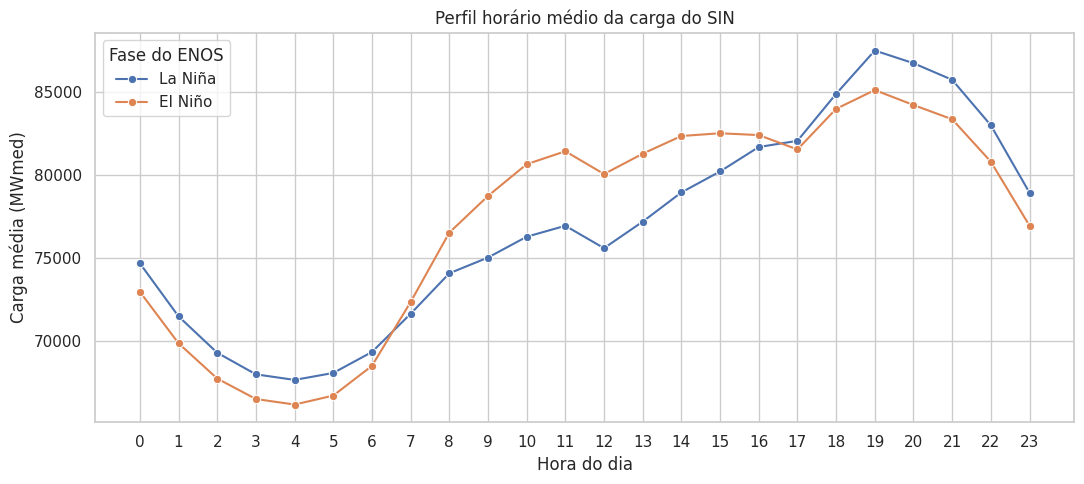

In [89]:
## grafico do perfil horario da carga
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=horario,
    x="hora",
    y="carga_media",
    hue="fase_enso",
    hue_order=["La Niña", "El Niño"],
    marker="o"
)

plt.title(
    "Perfil horário médio da carga do SIN"
)

plt.xlabel("Hora do dia")
plt.ylabel("Carga média (MWmed)")

plt.xticks(range(24))

plt.legend(
    title="Fase do ENOS"
)

plt.tight_layout()
plt.show()

In [90]:
##identificação dos horários de pico
picos_horarios = (
    horario.loc[
        horario.groupby(
            "fase_enso"
        )["carga_media"].idxmax()
    ]
    .sort_values(
        "fase_enso"
    )
)

display(picos_horarios)

,fase_enso,hora,carga_media
19,El Niño,19,"85,127.82"
43,La Niña,19,"87,508.40"


In [91]:
## identificação dos minimos

minimos_horarios = (
    horario.loc[
        horario.groupby(
            "fase_enso"
        )["carga_media"].idxmin()
    ]
    .sort_values(
        "fase_enso"
    )
)

display(minimos_horarios)

,fase_enso,hora,carga_media
4,El Niño,4,"66,193.93"
28,La Niña,4,"67,676.70"


### **Ocorrencia de cargas elevadas**

Para avaliar a ocorrência de valores elevados, foi utilizado o percentil 95 da carga considerando conjuntamente os períodos de El Niño e La Niña.

Dessa forma, um único limiar foi aplicado aos dois grupos, permitindo comparar a proporção de observações classificadas como carga elevada.

In [92]:
limite_p95 = (
    df_enso["val_carga"]
    .quantile(0.95)
)

print(
    f"Percentil 95: "
    f"{limite_p95:,.2f} MWmed"
)

df_enso["carga_elevada"] = (
    df_enso["val_carga"]
    >= limite_p95
)

Percentil 95: 92,624.02 MWmed


In [93]:
#frquencia de carga elevada

extremos = (
    df_enso
    .groupby("fase_enso")
    .agg(
        total_horas=(
            "val_carga",
            "size"
        ),
        horas_carga_elevada=(
            "carga_elevada",
            "sum"
        )
    )
)

extremos[
    "percentual_carga_elevada"
] = (
    extremos[
        "horas_carga_elevada"
    ]
    /
    extremos[
        "total_horas"
    ]
    * 100
)

display(extremos.round(2))

,total_horas,horas_carga_elevada,percentual_carga_elevada
fase_enso,,,
El Niño,8040,503,6.26
La Niña,5088,154,3.03


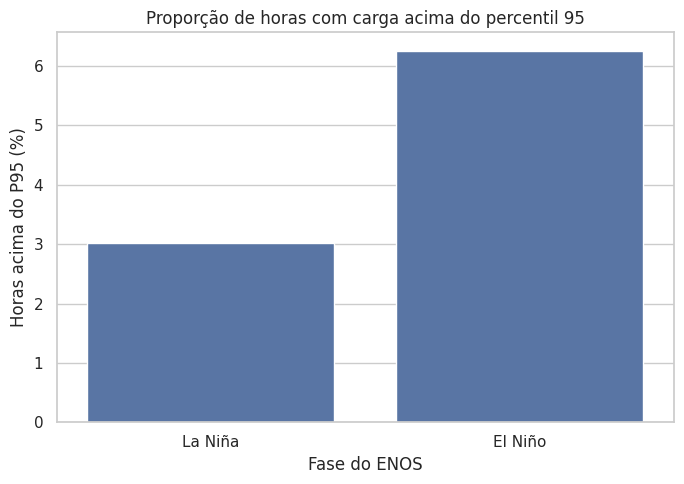

In [94]:
## grafico da proporção de horas com carga elevada

grafico_extremos = (
    extremos
    .reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=grafico_extremos,
    x="fase_enso",
    y="percentual_carga_elevada",
    order=["La Niña", "El Niño"]
)

plt.title(
    "Proporção de horas com carga acima do percentil 95"
)

plt.xlabel("Fase do ENOS")
plt.ylabel("Horas acima do P95 (%)")

plt.tight_layout()
plt.show()